# Student Performance Analysis and Prediction

## 1. Introduction

Student academic performance can be influenced by several factors, including study habits, previous academic results, family support, and school environment.

This project uses Python, data analysis, and machine learning techniques to investigate student performance in Mathematics and Portuguese.

The main objectives are:

- Analyze student academic performance using exploratory data analysis.
- Identify relationships between student characteristics and final grades.
- Develop early and late prediction models using Linear Regression.
- Compare model performance using MAE and R².
- Identify important predictive features using permutation importance.
- Evaluate model reliability using five-fold cross-validation.

The project uses the UCI Student Performance dataset.

## 2. Importing Libraries

This project uses several Python libraries for data analysis, visualization, and machine learning.

- **Pandas:** Data manipulation and analysis.
- **NumPy:** Numerical operations.
- **Matplotlib:** Data visualization.
- **Seaborn:** Statistical visualization.
- **Scikit-learn:** Machine learning, model evaluation, and cross-validation.

These libraries provide the tools required to explore the dataset and develop predictive models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Dataset Collection

The dataset used in this project is obtained from the UCI Machine Learning Repository.

It contains student records from two subjects:

- Mathematics: 395 records.
- Portuguese: 649 records.

The two datasets are combined into a single DataFrame containing 1,044 records.

A new column named `subject` is added to distinguish Mathematics and Portuguese records.

The final grade (`G3`) is used as the prediction target.

In [2]:
import pandas as pd
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/320/student%2Bperformance.zip"

response = requests.get(url, timeout=30)
response.raise_for_status()

outer_zip = zipfile.ZipFile(io.BytesIO(response.content))

if "student.zip" in outer_zip.namelist():
    inner_zip = zipfile.ZipFile(
        io.BytesIO(outer_zip.read("student.zip"))
    )
else:
    inner_zip = outer_zip

math_df = pd.read_csv(
    inner_zip.open("student-mat.csv"), sep=";"
)

portuguese_df = pd.read_csv(
    inner_zip.open("student-por.csv"), sep=";"
)

math_df["subject"] = "Mathematics"
portuguese_df["subject"] = "Portuguese"

student_df = pd.concat(
    [math_df, portuguese_df], ignore_index=True
)

# Preserve the Portuguese-only dataframe used in earlier analysis
df = portuguese_df.copy()

print("Mathematics records:", len(math_df))
print("Portuguese records:", len(portuguese_df))
print("Combined records:", len(student_df))

Mathematics records: 395
Portuguese records: 649
Combined records: 1044


## 4. Data Understanding

After combining the Mathematics and Portuguese datasets, the next step is to understand the structure and characteristics of the data.

The following operations are performed:

- Display the first five records to understand the dataset.
- Check the number of rows and columns.
- Inspect column names and data types.
- Generate descriptive statistics for numerical variables.
- Examine the distribution of student grades and other characteristics.

This step helps identify the structure, characteristics, and potential issues in the dataset before performing further analysis.

In [3]:
# Display first five records
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,Portuguese
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,Portuguese
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,Portuguese
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,Portuguese
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,Portuguese


In [4]:
# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (649, 34)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'subject']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason   

## 5. Data Cleaning

Data cleaning is performed to ensure the dataset is suitable for analysis and machine learning.

The following checks are carried out:

- Identify missing values in each column.
- Check for duplicate records.
- Verify that the dataset contains valid observations.
- Confirm that the subject labels are correctly assigned.

These checks help improve data quality and reduce potential errors during analysis.

In [5]:
# Check missing values in each column
print(df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
subject       0
dtype: int64


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [8]:
print("Average First Period Grade:", df["G1"].mean())
print("Average Second Period Grade:", df["G2"].mean())
print("Average Final Grade:", df["G3"].mean())

Average First Period Grade: 11.399075500770415
Average Second Period Grade: 11.570107858243452
Average Final Grade: 11.906009244992296


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand patterns, trends, and relationships within the student performance dataset.

The analysis focuses on:

- Distribution of final grades (G3).
- Relationship between study time and final grades.
- Relationship between student absences and final grades.
- Correlation between previous grades (G1 and G2) and final grades.
- Correlation between numerical student characteristics.

Visualizations such as histograms, scatter plots, bar charts, and correlation heatmaps are used to identify meaningful patterns.

EDA helps understand the dataset before building machine learning models. The observed relationships are statistical associations and do not necessarily imply causation.

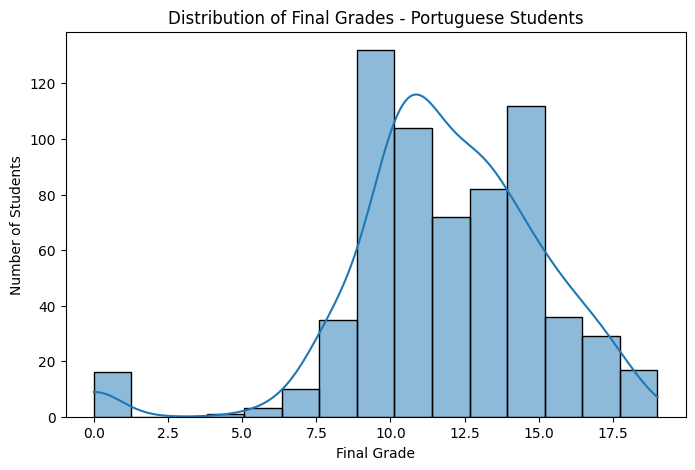

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=15, kde=True)

plt.title("Distribution of Final Grades - Portuguese Students")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

In [10]:
study_analysis = df.groupby("studytime")["G3"].mean()

print(study_analysis)

studytime
1    10.844340
2    12.091803
3    13.226804
4    13.057143
Name: G3, dtype: float64


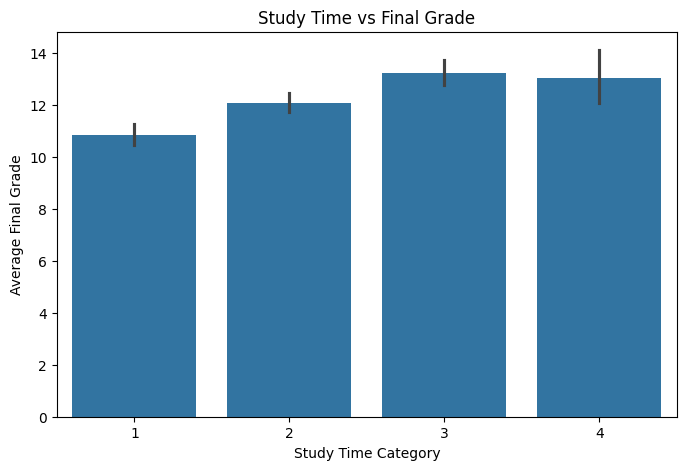

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(x="studytime", y="G3", data=df)

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")

plt.show()

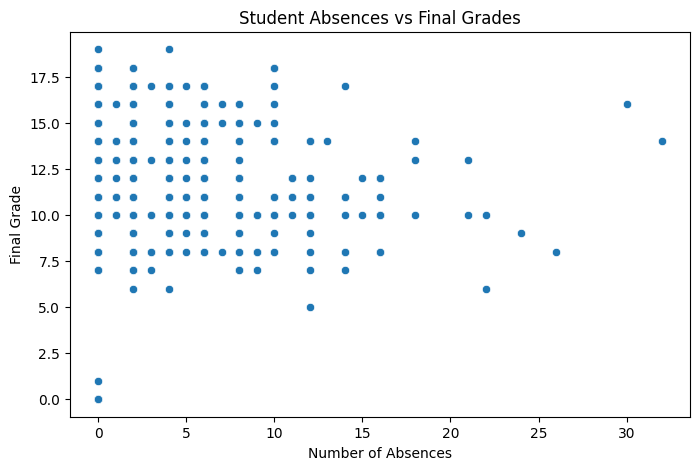

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3"
)

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.show()

           studytime  absences        G1        G2        G3
studytime   1.000000 -0.118389  0.260875  0.240498  0.249789
absences   -0.118389  1.000000 -0.147149 -0.124745 -0.091379
G1          0.260875 -0.147149  1.000000  0.864982  0.826387
G2          0.240498 -0.124745  0.864982  1.000000  0.918548
G3          0.249789 -0.091379  0.826387  0.918548  1.000000


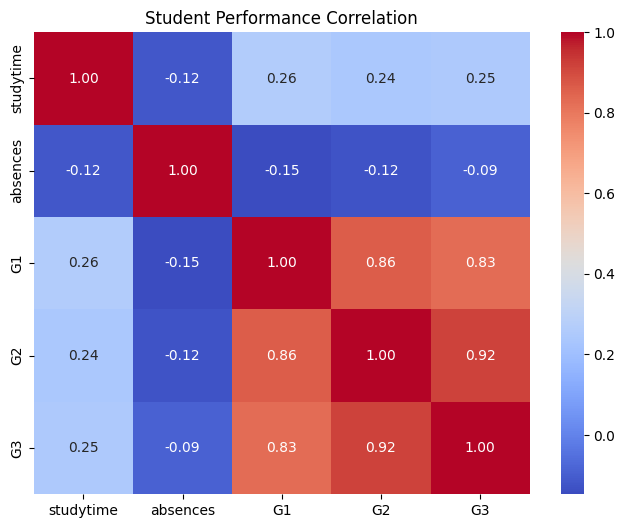

In [13]:
correlation = df[["studytime", "absences", "G1", "G2", "G3"]].corr()

print(correlation)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Performance Correlation")
plt.show()

In [14]:
print("Study time vs final grade:",
      df["studytime"].corr(df["G3"]))

print("Absences vs final grade:",
      df["absences"].corr(df["G3"]))

print("First grade vs final grade:",
      df["G1"].corr(df["G3"]))

Study time vs final grade: 0.24978868999886314
Absences vs final grade: -0.0913790564387561
First grade vs final grade: 0.8263871247890474


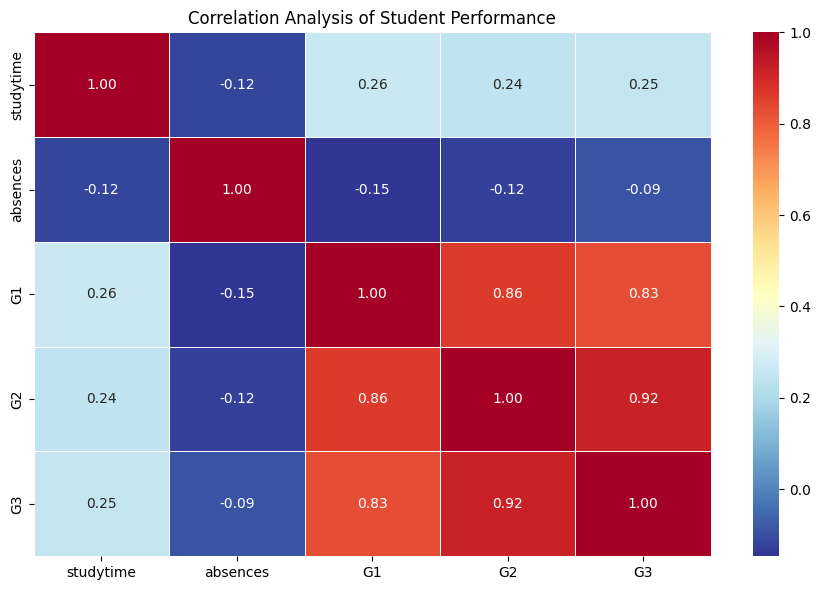

In [15]:
correlations = df[
    ["studytime", "absences", "G1", "G2", "G3"]
].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlations,
    annot=True,
    cmap="RdYlBu_r",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Analysis of Student Performance")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Machine Learning libraries imported!")

Machine Learning libraries imported!


In [17]:
# Input features
X = df[["studytime", "absences", "G1", "G2"]]

# Target variable
y = df["G3"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   studytime  absences  G1  G2
0          2         4   0  11
1          2         2   9  11
2          2         6  12  13
3          3         0  14  14
4          2         0  11  13

Target values:
0    11
1    11
2    12
3    14
4    13
Name: G3, dtype: int64


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 519
Testing records: 130


In [19]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [20]:
predictions = model.predict(X_test)

print("Actual Grades:", list(y_test[:10]))
print("Predicted Grades:", predictions[:10])

Actual Grades: [19, 12, 18, 11, 11, 17, 18, 8, 10, 11]
Predicted Grades: [18.64651374 11.31471485 18.7380403  11.19906892 11.69072293 16.86674065
 17.67067398  9.56094122 10.44030349 10.48359131]


In [21]:
mae = mean_absolute_error(y_test, predictions)

mse = mean_squared_error(y_test, predictions)

r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Mean Absolute Error: 0.7477392675349176
Mean Squared Error: 1.3720779659573386
R2 Score: 0.8592988178401069


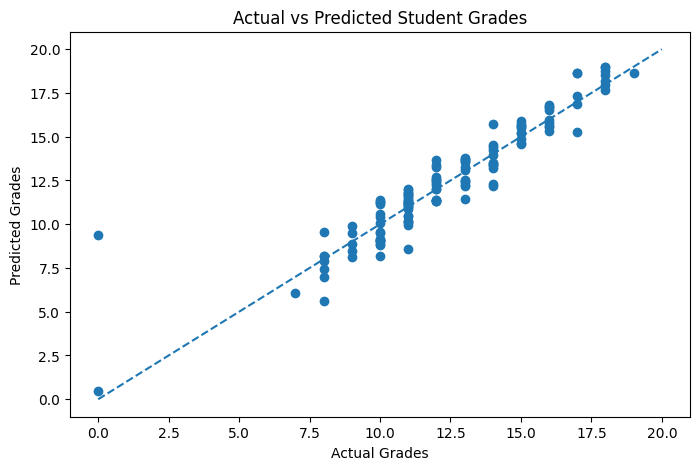

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions)

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")

plt.title("Actual vs Predicted Student Grades")

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--"
)

plt.show()

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Only study time and absences
X_A = df[["studytime", "absences"]]
y = df["G3"]

XA_train, XA_test, yA_train, yA_test = train_test_split(
    X_A, y, test_size=0.2, random_state=42
)

model_A = LinearRegression()
model_A.fit(XA_train, yA_train)

pred_A = model_A.predict(XA_test)

print("Model A - Study time and absences")
print("MAE:", mean_absolute_error(yA_test, pred_A))
print("MSE:", mean_squared_error(yA_test, pred_A))
print("R2:", r2_score(yA_test, pred_A))

Model A - Study time and absences
MAE: 2.30486003034338
MSE: 9.357258505668788
R2: 0.04045005736631069


In [24]:
X_B = df[["studytime", "absences", "G1", "G2"]]

XB_train, XB_test, yB_train, yB_test = train_test_split(
    X_B, y, test_size=0.2, random_state=42
)

model_B = LinearRegression()
model_B.fit(XB_train, yB_train)

pred_B = model_B.predict(XB_test)

print("Model B - All four features")
print("MAE:", mean_absolute_error(yB_test, pred_B))
print("MSE:", mean_squared_error(yB_test, pred_B))
print("R2:", r2_score(yB_test, pred_B))

Model B - All four features
MAE: 0.7477392675349176
MSE: 1.3720779659573386
R2: 0.8592988178401069


In [25]:
comparison = pd.DataFrame({
    "Model": ["Model A", "Model B"],
    "MAE": [
        mean_absolute_error(yA_test, pred_A),
        mean_absolute_error(yB_test, pred_B)
    ],
    "MSE": [
        mean_squared_error(yA_test, pred_A),
        mean_squared_error(yB_test, pred_B)
    ],
    "R2 Score": [
        r2_score(yA_test, pred_A),
        r2_score(yB_test, pred_B)
    ]
})

print(comparison)

     Model       MAE       MSE  R2 Score
0  Model A  2.304860  9.357259  0.040450
1  Model B  0.747739  1.372078  0.859299


In [26]:
importance = pd.DataFrame({
    "Feature": X_B.columns,
    "Coefficient": model_B.coef_
})

importance = importance.sort_values(
    by="Coefficient",
    ascending=False
)

print(importance)

     Feature  Coefficient
3         G2     0.879362
2         G1     0.188004
0  studytime     0.118717
1   absences     0.024119


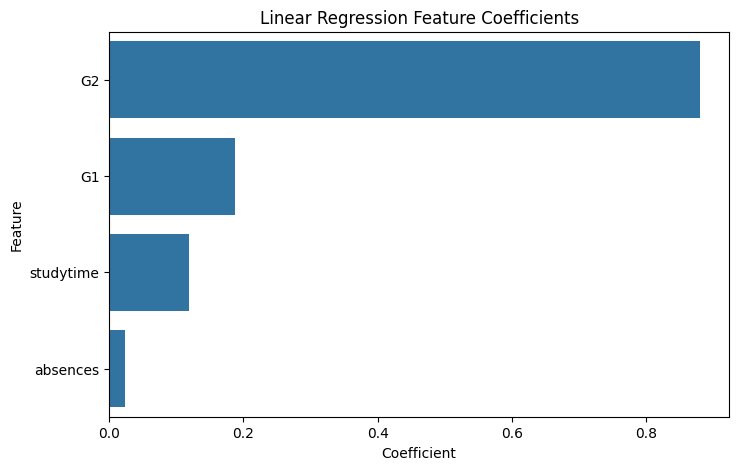

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x="Coefficient",
    y="Feature"
)

plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.show()

In [28]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression

X = df[["studytime", "absences", "G1", "G2"]]
y = df["G3"]

model = LinearRegression()

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    model, X, y,
    cv=cv,
    scoring="r2"
)

print("R² scores:", scores)
print("Average R²:", scores.mean())
print("Standard deviation:", scores.std())

R² scores: [0.85929882 0.855316   0.78473684 0.87666054 0.87148366]
Average R²: 0.8494991729554556
Standard deviation: 0.03330190843092364


In [29]:
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (649, 34)

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,Portuguese
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,Portuguese
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,Portuguese
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,Portuguese
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,Portuguese



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    

In [30]:
import pandas as pd
import requests
import zipfile
import io

# Correct UCI download URL
url = "https://archive.ics.uci.edu/static/public/320/student%2Bperformance.zip"

response = requests.get(url)
response.raise_for_status()

# Open outer ZIP
outer_zip = zipfile.ZipFile(io.BytesIO(response.content))

print("Files found:", outer_zip.namelist())

# Extract inner ZIP if present
if "student.zip" in outer_zip.namelist():
    inner_zip = zipfile.ZipFile(
        io.BytesIO(outer_zip.read("student.zip"))
    )
else:
    inner_zip = outer_zip

# Load both subjects
math_df = pd.read_csv(
    inner_zip.open("student-mat.csv"), sep=";"
)

portuguese_df = pd.read_csv(
    inner_zip.open("student-por.csv"), sep=";"
)

# Add subject labels
math_df["subject"] = "Mathematics"
portuguese_df["subject"] = "Portuguese"

# Combine datasets
student_df = pd.concat(
    [math_df, portuguese_df],
    ignore_index=True
)

print("\nMathematics:", len(math_df))
print("Portuguese:", len(portuguese_df))
print("Combined:", len(student_df))

display(student_df.head())

Files found: ['.student.zip_old', 'student.zip']

Mathematics: 395
Portuguese: 649
Combined: 1044


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,Mathematics
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,Mathematics
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,Mathematics
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,Mathematics
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,Mathematics


## 7. Subject-wise Performance Analysis

This section compares student performance between Mathematics and Portuguese.

The analysis examines:

- Average first-period grade (G1).
- Average second-period grade (G2).
- Average final grade (G3).
- Average student absences.
- Average study time.

A comparison of average final grades is also visualized using a bar chart.

This analysis helps identify differences in academic performance and student characteristics across the two subjects.

In [31]:
# Compare average grades by subject

subject_comparison = student_df.groupby("subject").agg({
    "G1": "mean",
    "G2": "mean",
    "G3": "mean",
    "absences": "mean",
    "studytime": "mean"
}).round(2)

print("Subject-wise Performance Comparison:")
display(subject_comparison)

Subject-wise Performance Comparison:


,G1,G2,G3,absences,studytime
subject,,,,,
Mathematics,10.91,10.71,10.42,5.71,2.04
Portuguese,11.40,11.57,11.91,3.66,1.93


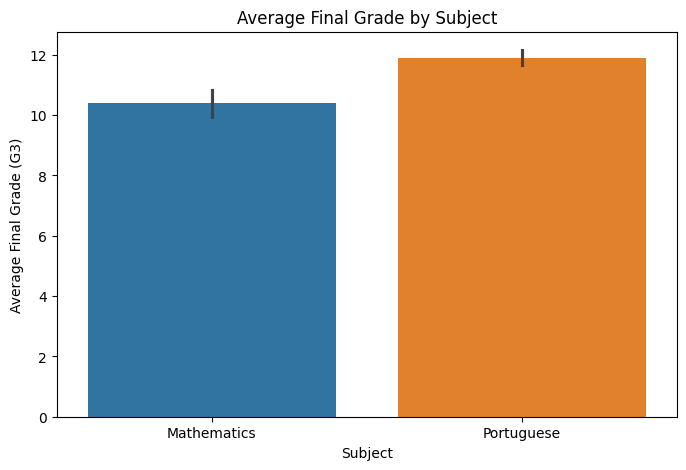

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=student_df,
    x="subject",
    y="G3",
    hue="subject",
    legend=False
)

plt.title("Average Final Grade by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Final Grade (G3)")
plt.show()

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.metrics import mean_squared_error

subjects = ["Mathematics", "Portuguese"]

results = []

features = ["studytime", "absences", "G1", "G2"]
target = "G3"

for subject in subjects:

    data = student_df[
        student_df["subject"] == subject
    ]

    X = data[features]
    y = data[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Subject": subject,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "R2 Score": r2_score(y_test, predictions)
    })

comparison = pd.DataFrame(results)

print("Subject-wise Model Performance:")
display(comparison.round(4))

Subject-wise Model Performance:


,Subject,MAE,MSE,R2 Score
0,Mathematics,1.3126,4.1790,0.7962
1,Portuguese,0.7477,1.3721,0.8593


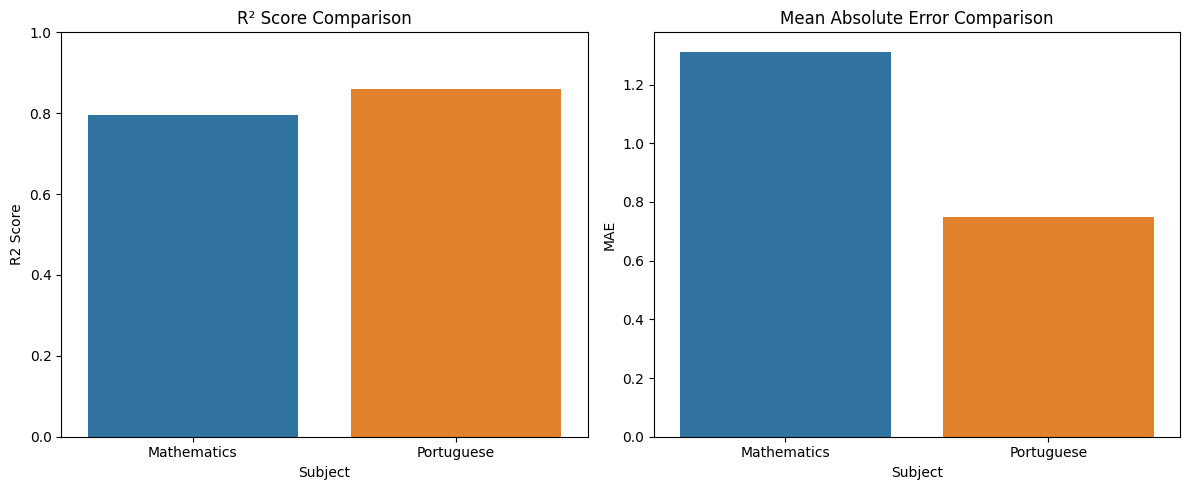

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare R2 scores
sns.barplot(
    data=comparison,
    x="Subject",
    y="R2 Score",
    hue="Subject",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("R² Score Comparison")
axes[0].set_ylim(0, 1)

# Compare MAE
sns.barplot(
    data=comparison,
    x="Subject",
    y="MAE",
    hue="Subject",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Mean Absolute Error Comparison")

plt.tight_layout()
plt.show()

In [35]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
import pandas as pd

features = ["studytime", "absences", "G1", "G2"]
target = "G3"

cv_results = []

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]

    X = data[features]
    y = data[target]

    model = LinearRegression()

    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=kfold,
        scoring="r2"
    )

    cv_results.append({
        "Subject": subject,
        "Average R2": scores.mean(),
        "Standard Deviation": scores.std(),
        "Fold Scores": scores.round(4).tolist()
    })

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison)

,Subject,Average R2,Standard Deviation,Fold Scores
0,Mathematics,0.819193,0.031912,"[0.7962, 0.8228, 0.8549, 0.8506, 0.7714]"
1,Portuguese,0.849499,0.033302,"[0.8593, 0.8553, 0.7847, 0.8767, 0.8715]"


## 8. Linear Regression Model Development

Linear Regression is used to predict students' final academic grades (G3) based on selected input features.

The initial model uses:

- Study time
- Absences
- First-period grade (G1)
- Second-period grade (G2)

The dataset is divided into training and testing sets using an 80:20 split.

The model is trained using the training data and evaluated using:

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- R² Score

These metrics help measure prediction errors and the model's ability to explain variation in final grades.


 Mathematics
Cross-validated MAE: 1.1852
Mean residual: -0.0038


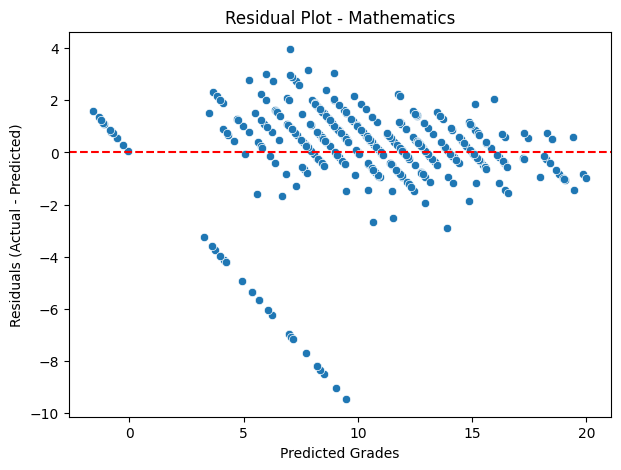


 Portuguese
Cross-validated MAE: 0.7935
Mean residual: -0.0081


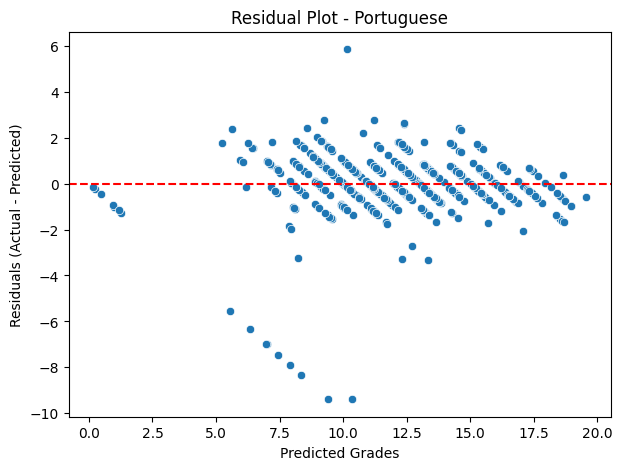

In [36]:
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

features = ["studytime", "absences", "G1", "G2"]

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]

    X = data[features]
    y = data["G3"]

    model = LinearRegression()

    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    predictions = cross_val_predict(
        model, X, y, cv=kfold
    )

    residuals = y - predictions

    print("\n", subject)
    print("Cross-validated MAE:",
          round(mean_absolute_error(y, predictions), 4))
    print("Mean residual:",
          round(residuals.mean(), 4))

    plt.figure(figsize=(7, 5))
    sns.scatterplot(x=predictions, y=residuals)

    plt.axhline(0, color="red", linestyle="--")
    plt.xlabel("Predicted Grades")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.title(f"Residual Plot - {subject}")
    plt.show()

## 9. Early vs. Late Prediction

This project investigates two different prediction scenarios.

### Early Prediction

The early prediction model uses eight student-related features without previous examination grades.

Its purpose is to investigate whether student characteristics and study-related factors can help estimate final academic performance before earlier examination results are available.

### Late Prediction

The late prediction model uses study time, absences, G1, and G2.

Its purpose is to investigate how previous academic grades improve the prediction of final performance.

Both models are evaluated separately for Mathematics and Portuguese using five-fold cross-validation.

In [37]:
early_features = [
    "studytime",
    "absences",
    "age",
    "failures",
    "schoolsup",
    "famsup",
    "internet",
    "higher"
]

print("Early prediction features:")
print(early_features)

print("\nNumber of features:", len(early_features))

Early prediction features:
['studytime', 'absences', 'age', 'failures', 'schoolsup', 'famsup', 'internet', 'higher']

Number of features: 8


In [38]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

numeric_features = [
    "studytime", "absences", "age", "failures"
]

categorical_features = [
    "schoolsup", "famsup", "internet", "higher"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

early_results = []

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]

    X = data[early_features]
    y = data["G3"]

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])

    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    predictions = cross_val_predict(
        model, X, y, cv=kfold
    )

    mae = mean_absolute_error(y, predictions)
    r2 = r2_score(y, predictions)

    early_results.append({
        "Subject": subject,
        "Early Prediction MAE": round(mae, 4),
        "Early Prediction R2": round(r2, 4)
    })

display(pd.DataFrame(early_results))

,Subject,Early Prediction MAE,Early Prediction R2
0,Mathematics,3.3221,0.0927
1,Portuguese,2.0802,0.2300


## 10. Model Evaluation and Comparison

The models are evaluated using five-fold cross-validation with out-of-fold predictions.

The evaluation metrics are:

- **MAE:** Measures the average absolute difference between actual and predicted grades.
- **R² Score:** Measures the proportion of variation in final grades explained by the model.

The results are compared across Mathematics and Portuguese to understand the differences between early and late prediction performance.

Lower MAE and higher R² indicate better predictive performance.

In [39]:
late_results = [
    {"Subject": "Mathematics", "Late Prediction MAE": 1.1852,
     "Late Prediction R2": 0.8192},
    {"Subject": "Portuguese", "Late Prediction MAE": 0.7935,
     "Late Prediction R2": 0.8495}
]

late_df = pd.DataFrame(late_results)
early_df = pd.DataFrame(early_results)

final_comparison = pd.merge(
    early_df,
    late_df,
    on="Subject"
)

display(final_comparison.round(4))

,Subject,Early Prediction MAE,Early Prediction R2,Late Prediction MAE,Late Prediction R2
0,Mathematics,3.3221,0.0927,1.1852,0.8192
1,Portuguese,2.0802,0.2300,0.7935,0.8495


## 11. Feature Importance Analysis

Permutation importance was used to evaluate how much each input feature contributes to the predictive performance of the models.

The analysis was performed separately for Mathematics and Portuguese. Feature importance was also evaluated across five cross-validation folds to obtain average importance values and standard deviations.

**Key observations:**
- `failures` showed the strongest predictive contribution in both subjects.
- `higher` and `studytime` showed greater predictive importance in Portuguese.
- `schoolsup` and `age` showed greater predictive importance in Mathematics.
- Some features had small or negative average importance, suggesting that they did not consistently improve model performance.

**Interpretation:** Permutation importance measures predictive usefulness, not cause and effect. A negative value means that shuffling a feature slightly improved the model's performance in that evaluation.

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
import pandas as pd

importance_results = []

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]

    X = data[early_features]
    y = data["G3"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])

    model.fit(X_train, y_train)

    importance = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=20,
        random_state=42
    )

    subject_importance = pd.DataFrame({
        "Feature": X.columns,
        "Importance": importance.importances_mean
    }).sort_values("Importance", ascending=False)

    subject_importance["Subject"] = subject

    importance_results.append(subject_importance)

    print("\n", subject, "Feature Importance")
    display(subject_importance.round(4))


 Mathematics Feature Importance


,Feature,Importance,Subject
3,failures,0.2875,Mathematics
4,schoolsup,0.0491,Mathematics
2,age,0.0481,Mathematics
1,absences,-0.0238,Mathematics
0,studytime,-0.0424,Mathematics
7,higher,-0.0439,Mathematics
5,famsup,-0.0577,Mathematics
6,internet,-0.0628,Mathematics



 Portuguese Feature Importance


,Feature,Importance,Subject
3,failures,0.2195,Portuguese
7,higher,0.0891,Portuguese
0,studytime,0.0465,Portuguese
6,internet,0.0198,Portuguese
2,age,0.0050,Portuguese
5,famsup,0.0032,Portuguese
1,absences,0.0017,Portuguese
4,schoolsup,0.0016,Portuguese


In [41]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold
import numpy as np

importance_cv_results = []

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]
    X = data[early_features]
    y = data["G3"]

    kfold = KFold(n_splits=5, shuffle=True, random_state=42)

    fold_importances = []

    for train_idx, test_idx in kfold.split(X):

        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", LinearRegression())
        ])

        model.fit(X_train, y_train)

        importance = permutation_importance(
            model,
            X_test,
            y_test,
            scoring="neg_mean_absolute_error",
            n_repeats=20,
            random_state=42
        )

        fold_importances.append(importance.importances_mean)

    mean_importance = np.mean(fold_importances, axis=0)
    std_importance = np.std(fold_importances, axis=0)

    result = pd.DataFrame({
        "Feature": early_features,
        "Mean Importance": mean_importance,
        "Std Deviation": std_importance,
        "Subject": subject
    }).sort_values("Mean Importance", ascending=False)

    importance_cv_results.append(result)

    print("\n", subject, "5-Fold Feature Importance")
    display(result.round(4))


 Mathematics 5-Fold Feature Importance


,Feature,Mean Importance,Std Deviation,Subject
3,failures,0.3133,0.1310,Mathematics
4,schoolsup,0.0825,0.0184,Mathematics
2,age,0.0752,0.0544,Mathematics
5,famsup,0.0270,0.0503,Mathematics
6,internet,0.0037,0.0333,Mathematics
1,absences,0.0006,0.0289,Mathematics
7,higher,-0.0147,0.0308,Mathematics
0,studytime,-0.0347,0.0552,Mathematics



 Portuguese 5-Fold Feature Importance


,Feature,Mean Importance,Std Deviation,Subject
3,failures,0.2267,0.0763,Portuguese
7,higher,0.1375,0.0741,Portuguese
0,studytime,0.0756,0.0340,Portuguese
4,schoolsup,0.0285,0.0259,Portuguese
6,internet,0.0245,0.0226,Portuguese
2,age,0.0064,0.0030,Portuguese
1,absences,0.0046,0.0037,Portuguese
5,famsup,-0.0019,0.0029,Portuguese


In [42]:
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

early_features = [
    "studytime", "absences", "age", "failures",
    "schoolsup", "famsup", "internet", "higher"
]

late_features = ["studytime", "absences", "G1", "G2"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

consistent_results = []

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]
    y = data["G3"]

    for stage, features in [
        ("Early", early_features),
        ("Late", late_features)
    ]:

        X = data[features]

        if stage == "Early":
            preprocessor = ColumnTransformer([
                ("categorical",
                 OneHotEncoder(handle_unknown="ignore"),
                 ["schoolsup", "famsup", "internet", "higher"])
            ], remainder="passthrough")

            model = Pipeline([
                ("preprocessor", preprocessor),
                ("regressor", LinearRegression())
            ])
        else:
            model = LinearRegression()

        predictions = cross_val_predict(
            model, X, y, cv=cv
        )

        consistent_results.append({
            "Subject": subject,
            "Stage": stage,
            "MAE": mean_absolute_error(y, predictions),
            "R2": r2_score(y, predictions)
        })

consistent_comparison = pd.DataFrame(consistent_results)

display(consistent_comparison.round(4))

,Subject,Stage,MAE,R2
0,Mathematics,Early,3.3221,0.0927
1,Mathematics,Late,1.1852,0.8217
2,Portuguese,Early,2.0802,0.2300
3,Portuguese,Late,0.7935,0.8442


## 12. Results and Discussion

The models were evaluated using five-fold cross-validation and out-of-fold predictions. The following table compares early-stage and late-stage prediction performance.

| Subject | Prediction Stage | MAE | R² |
|---|---|---:|---:|
| Mathematics | Early | 3.3221 | 0.0927 |
| Mathematics | Late | 1.1852 | 0.8217 |
| Portuguese | Early | 2.0802 | 0.2300 |
| Portuguese | Late | 0.7935 | 0.8442 |

**Key findings:**
- Late-stage models performed substantially better for both subjects.
- Previous examination grades (G1 and G2) provided strong predictive information about final grades (G3).
- Early-stage prediction had limited performance, particularly for Mathematics.
- Portuguese prediction achieved lower MAE and higher R² than Mathematics at both stages.

**Interpretation:** The results indicate that previous examination grades are highly useful for predicting final academic performance. However, these results reflect this dataset and do not guarantee similar accuracy for students from other schools.

## 13. Conclusion

This project explored student academic performance in Mathematics and Portuguese using exploratory data analysis and machine learning.

Linear Regression models were developed to predict final grades (G3) at two different stages: early prediction using student-related information and late prediction using previous examination grades.

The results showed that late-stage models achieved substantially better predictive performance than early-stage models. Previous examination grades (G1 and G2) were important predictors of final academic performance.

Permutation importance helped identify features that contributed to prediction, with previous academic failures showing the strongest contribution in the early prediction analysis.

Overall, this project demonstrates how data analysis and machine learning can be applied to educational datasets to study academic performance and explore student grade prediction.

## 14. Limitations and Future Improvements

### Limitations

- **Limited dataset:** The analysis uses data from two Portuguese schools, so the findings may not represent all student populations.
- **No external validation:** The models were evaluated using cross-validation on the available dataset, not on students from entirely different schools.
- **Limited early prediction accuracy:** Early-stage models showed relatively low R² values, especially for Mathematics.
- **Dependence on previous grades:** Late-stage prediction uses G1 and G2, which are already available examination results. Therefore, it is more suitable for later-stage prediction than early intervention.
- **No causal conclusions:** Feature importance and correlations indicate predictive relationships, not proof that a feature causes a change in academic performance.
- **No student identifiers:** The dataset does not provide student IDs to reliably match records across the Mathematics and Portuguese files.

### Future Improvements

- Evaluate additional machine learning algorithms, such as Random Forest and Gradient Boosting.
- Explore hyperparameter tuning to improve model performance.
- Test the models on independent datasets from other schools.
- Investigate additional features that may improve early-stage prediction.
- Develop an interactive dashboard to make the analysis easier to explore.
- Study model fairness and prediction reliability across different student groups.